In [2]:
import subprocess
from functools import reduce
import matplotlib.pyplot as plt
import numpy as np
from analysis import generate_data

kernel_x_y_fc = (4, 4, 10) # x y <channels> fc
input_x_y_c = (1000,1000,40)
stride=2
samples=3
single_batch_size=8
batch_counts=15
f = lambda x, y: generate_data(
    kernel_arg="%d,%d,%d" % y,
    input_arg="%d,%d,%d" % x,
    samples=samples, single_batch_size=single_batch_size,
    batch_counts=batch_counts, cpu_or_gpu='gpu', cpu_threads=0,
    stride=stride, gpu_detailed_timing=False,
    gpu_local_mem=False, gpu_pinned_mem=True,
    gpu_full_duplex=True)

In [1]:
import subprocess
from functools import reduce
import matplotlib.pyplot as plt
import numpy as np
from analysis import generate_data

kernel_x_y_fc = (4, 4, 10) # x y <channels> fc
input_x_y_c = (1000,1000,40)
stride=2
samples=3
single_batch_size=8
batch_counts=15
f2 = lambda x, y: generate_data(
    kernel_arg="%d,%d,%d" % y,
    input_arg="%d,%d,%d" % x,
    samples=samples, single_batch_size=single_batch_size,
    batch_counts=batch_counts, cpu_or_gpu='gpu', cpu_threads=0,
    stride=stride, gpu_detailed_timing=False,
    gpu_local_mem=True, gpu_pinned_mem=False,
    gpu_full_duplex=False, )


kernel_x_y_fc = (10, 10, 5)
input_x_y_c = (1000, 1000, 3)
compute_time_inp_size = []
input_size = []
theory_time_inp_size = []
theory_just_compute_time_inp_size = []

scale = 1
for i in range(2, scale * 50, 10):
    print("      --> %d" % i)
    kernel_x_y_fc = (i, i, int(scale * 30 * (i // 60) + 1))

    res = f(input_x_y_c, kernel_x_y_fc)['gpu_overall_time_0']
    res = np.median(res)
    compute_time_inp_size.append(res)

    input_size.append(reduce(lambda x, a: x * a, kernel_x_y_fc, 1) * 1)
    res = f2(input_x_y_c, kernel_x_y_fc)['gpu_overall_time_0']
    res = np.median(res)
    theory_time_inp_size.append(res)

plt.figure(figsize=(12, 6))
plt.plot(input_size, compute_time_inp_size, label='Measured time with proper auto caching')
plt.plot(input_size, theory_time_inp_size, label='Measured time with bad worker order')
plt.xlabel('Input size')
plt.ylabel('Time (ms)')
plt.legend()

      --> 2


NameError: name 'f' is not defined

In [16]:
def parse_device_info(exe_path):
    # Run the executable
    completed_process = subprocess.run(
        [exe_path],
        capture_output=True,
        text=True,
        check=False
    )
    # Parse lines with a colon
    data = {}
    for line in completed_process.stdout.splitlines():
        if ':' in line:
            key, val = line.split(':', 1)
            data[key.strip()] = val.strip()
    return data

device_info = parse_device_info('../bin/device_info')
device_info['boost clock per core'] = \
    int(float(device_info['Max clock frequency'][:-3]) * 1e6
        * 2)
device_info['byte_move_speed'] = 1010 * 1e9  # 112.1 GB/s
device_info['local_byte_move_speed'] = 100 * 1e9

In [17]:
device_info

{'Platform': 'NVIDIA CUDA',
 'Device name': 'NVIDIA GeForce RTX 4090',
 'Device type': 'GPU',
 'Compute units (C)': '128',
 'Local mem per CU (L_dev)': '48 KiB',
 'Max WG size (WG_max)': '1024',
 'Max WI dims (x,y,z)': '1024 1024 64',
 'Compiler-max WG size (WG_kernel)': '256',
 'Static local mem (L_static)': '516 B',
 'Dynamic local mem (L_dyn per WG)': '512 B',
 'Max WIs per WG limited by local mem': '12159',
 'Usable WG size with all caps applied': '256',
 'Resident WGs per CU (local-mem-only)': '47',
 'Theoretical max WGs on device': '6016',
 'Compute units': '128',
 'Estimated total cores': '16384',
 'Max clock frequency': '2565 MHz',
 'Estimated max speed': '84.0499 TFlops',
 'boost clock per core': 5130000000,
 'byte_move_speed': 1010000000000.0,
 'local_byte_move_speed': 100000000000.0}

In [ ]:
import os
os.listdir('../bin')

In [ ]:
kernel_x_y_fc = (10, 10, 5)

f2 = lambda x, y: generate_data(
    kernel_arg="%d,%d,%d" % y,
    input_arg="%d,%d,%d" % x,
    samples=5, single_batch_size=single_batch_size,
    batch_counts=batch_counts, cpu_or_gpu='gpu', cpu_threads=0,
    stride=stride, gpu_detailed_timing=False,
    gpu_local_mem=True, gpu_pinned_mem=False,
    gpu_full_duplex=False)

input_x_y_c = (1000, 1000, 3)
compute_time_inp_size = []
input_size = []
theory_time_inp_size = []
theory_just_compute_time_inp_size = []

scale = 1
for i in range(2, scale * 60, 10):
    print("      --> %d" % i)
    kernel_x_y_fc = (i, i, int(scale * 30 * (i // 60) + 1))

    res = f(input_x_y_c, kernel_x_y_fc)['gpu_overall_time_0']
    res = np.median(res)
    compute_time_inp_size.append(res)

    input_size.append(reduce(lambda x, a: x * a, kernel_x_y_fc, 1) * 1)
    res = f2(input_x_y_c, kernel_x_y_fc)['gpu_overall_time_0']
    res = np.median(res)
    theory_time_inp_size.append(res)

plt.figure(figsize=(12, 6))
plt.plot(input_size, compute_time_inp_size, label='Measured time')
plt.plot(input_size, theory_time_inp_size, label='Measured time local mem')
plt.xlabel('Input size')
plt.ylabel('Time (ms)')
plt.legend()

In [ ]:
kernel_x_y_fc = (10, 10, 5)

f2 = lambda x, y: generate_data(
    kernel_arg="%d,%d,%d" % y,
    input_arg="%d,%d,%d" % x,
    samples=5, single_batch_size=single_batch_size,
    batch_counts=batch_counts, cpu_or_gpu='gpu', cpu_threads=0,
    stride=stride, gpu_detailed_timing=False,
    gpu_local_mem=True, gpu_pinned_mem=False,
    gpu_full_duplex=False)

input_x_y_c = (1000, 1000, 3)
# compute_time_inp_size = []
input_size = []
theory_time_inp_size = []
theory_just_compute_time_inp_size = []

scale = 1
for i in range(2, scale * 60, 10):
    print("      --> %d" % i)
    kernel_x_y_fc = (i, i, int(scale * 30 * (i // 60) + 1))

    res = f(input_x_y_c, kernel_x_y_fc)['gpu_overall_time_0']
    res = np.median(res)
    # compute_time_inp_size.append(res)

    input_size.append(reduce(lambda x, a: x * a, kernel_x_y_fc, 1) * 1)
    res = f2(input_x_y_c, kernel_x_y_fc)['gpu_overall_time_0']
    res = np.median(res)
    theory_time_inp_size.append(res)

plt.figure(figsize=(12, 6))
plt.plot(input_size, compute_time_inp_size, label='Measured time')
plt.plot(input_size, theory_time_inp_size, label='Measured time local mem')
plt.xlabel('Input size')
plt.ylabel('Time (ms)')
plt.legend()

In [25]:
def calculate_conv2d_ops(input_x_y_c: list, kernel_x_y_fc: list):
    C = input_x_y_c[2]   # channel_count
    w = input_x_y_c[0] # width
    h = input_x_y_c[1] # height
    Fw = kernel_x_y_fc[0] # filt_w
    Fh = kernel_x_y_fc[1] # filt_h

    # --- 1. Calculate Total Compute Operations ---
    # This is the sum of all integer and floating-point operations.

    # Integer operations formula: 11 (setup/final) + 2*C (outer loop) +
    # 2*C*Fh (middle loop) + 24*C*Fh*Fw (inner loop)
    integer_ops = 11 + (2 * C) + (2 * C * Fh) + (24 * C * Fh * Fw)

    # Floating-point operations formula: 3 (final) + 3*C*Fh*Fw (inner loop)
    float_ops = 3 + (3 * C * Fh * Fw)

    # Total compute is the sum of all arithmetic operations
    total_compute_ops = integer_ops + float_ops
    total_compute_ops = 11+Fh * Fw * (5 + C*(2+9*2+5))

    # assuming 35% of the operations were assignments to local memory of size 1.5 bytes
    bytes_moved_local = 0.35 * total_compute_ops * 1.5

    # --- 2. Calculate Total VRAM Memory Accesses ---
    # This includes all reads from and writes to global memory.

    # # Memory access formula: 1 (write) + C*Fh*Fw (reads image) + Fh*Fw (rad kernel)
    total_memory_ops = 1 + ((C+1) * Fh * Fw)

    out_bytes, filter_bytes, input_bytes = 4, 4, 1
    total_bytes = 1*out_bytes + (C * Fh * Fw)*input_bytes + (1 * Fh * Fw)*filter_bytes  # bytes

    return total_compute_ops, total_memory_ops, total_bytes, bytes_moved_local


def theoretical_info(input_x_y_c, kernel_x_y_fc):
    # app processing times with local mem off
    operation_per_pixel , memory_ops_per_pixel, bytes_moved_per_pixel, bytes_moved_local_per_pixel = calculate_conv2d_ops(input_x_y_c, kernel_x_y_fc)

    # === 1. Compute output spatial dimensions (VALID padding) ===
    H_in, W_in, C_in = input_x_y_c
    K_h, K_w, C_out = kernel_x_y_fc
    H_out = (H_in - K_h) // stride + 1
    W_out = (W_in - K_w) // stride + 1
    out_size_per_image = H_out * W_out * C_out
    total_output_pixel_count = (single_batch_size * out_size_per_image) * batch_counts

    compute_units_needed = total_output_pixel_count
    rounds_of_parallel_compute = np.ceil(compute_units_needed/float(device_info['Estimated total cores'])) # no fractional rounds
    time_per_pixel = operation_per_pixel / device_info['boost clock per core']
    gpu_compute_time =  rounds_of_parallel_compute * time_per_pixel *1000 # ms
    compute_done = operation_per_pixel * total_output_pixel_count

    # overlap from x,y axis and also the same input pixels per kernels
    temp = 1-max(0, K_h-stride)/(K_h)
    overlap_area_ratio = 1/C_out * temp
    bytes_moved = bytes_moved_per_pixel * total_output_pixel_count * overlap_area_ratio
    bytes_moved_local = bytes_moved_local_per_pixel * total_output_pixel_count

    gpu_memory_time = bytes_moved / device_info['byte_move_speed'] *1000 *2# ms
    gpu_memory_time += bytes_moved_local / device_info['local_byte_move_speed'] *\
                       1000/float(device_info['Estimated total cores'])  # ms

    outp = {
        "Output feature map size": out_size_per_image * 4,  # bytes
        # "Total FLOPs needed": flops / 1e9,  # G-Flops
        "Ideal DRAM traffic": bytes_moved / 1e6,  # MB
        "Ideal cache traffic": bytes_moved_local / 1e6,  # MB
        "Arithmetic intensity": compute_done / bytes_moved,  # FLOPs/byte
        "Time-spent compute": gpu_compute_time,  # ms
        "Time-spent memory": gpu_memory_time,  # ms
        "Time-spent overall": gpu_compute_time+gpu_memory_time,  # ms
    }
    return outp
kernel_x_y_fc = (10, 10, 5)
input_x_y_c = (1000, 1000, 3)
theoretical_info(input_x_y_c, kernel_x_y_fc)

{'Output feature map size': 4920320,
 'Ideal DRAM traffic': 4156.686336,
 'Ideal cache traffic': 620812.76544,
 'Arithmetic intensity': 284.4815340909091,
 'Time-spent compute': np.float64(14.070001949317739),
 'Time-spent memory': 8.609976092891397,
 'Time-spent overall': np.float64(22.679978042209136)}

      --> 100
      --> 200
      --> 300
      --> 400
      --> 500
      --> 600
      --> 700
      --> 800
      --> 900
      --> 1000
      --> 1100
      --> 1200


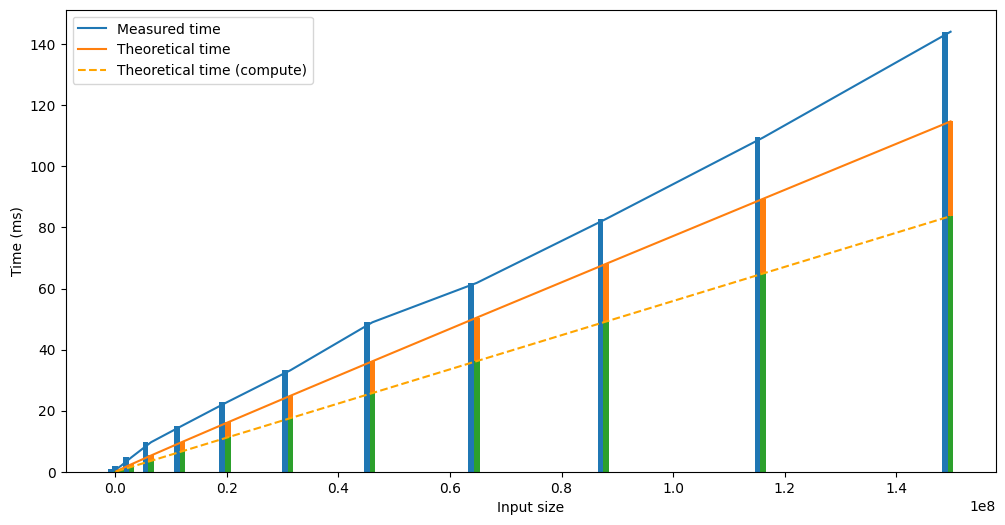

In [26]:
kernel_x_y_fc = (10, 10, 5)

# compute_time_inp_size = []
input_size = []
theory_time_inp_size = []
theory_just_compute_time_inp_size = []

scale = 1
for i in range(100, scale * 1300, 100):
    print("      --> %d" % i)
    input_x_y_c = (i, i, int(scale * 13 * (i / 1300) + 1))

    # res = f(input_x_y_c, kernel_x_y_fc)['gpu_overall_time_0']
    # res = np.median(res)
    # compute_time_inp_size.append(res)

    input_size.append(reduce(lambda x, a: x * a, input_x_y_c, 1) * single_batch_size)

    res = theoretical_info(input_x_y_c, kernel_x_y_fc)
    theory_time_inp_size.append(res['Time-spent overall'])
    theory_just_compute_time_inp_size.append(res['Time-spent compute'])

plt.figure(figsize=(12, 6))
plt.plot(input_size, compute_time_inp_size, label='Measured time')
plt.plot(input_size, theory_time_inp_size, label='Theoretical time')
plt.plot(input_size, theory_just_compute_time_inp_size, label='Theoretical time (compute)', linestyle='--', color='orange')
width = 1e6
plt.bar(np.array(input_size)-width, compute_time_inp_size, width=width)
plt.bar(np.array(input_size), theory_time_inp_size, width=width)
plt.bar(np.array(input_size), theory_just_compute_time_inp_size, width=width,)
plt.xlabel('Input size')
plt.ylabel('Time (ms)')
plt.legend()


      --> 2
      --> 12
      --> 22
      --> 32
      --> 42
      --> 52


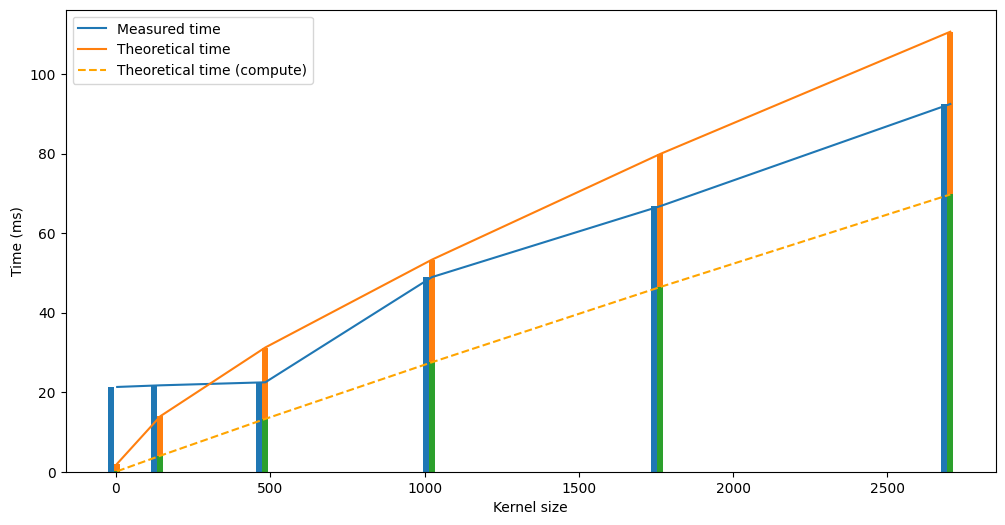

In [27]:
input_x_y_c = (1000, 1000, 3)

# compute_time_kernel_size = []
kernel_size = []
theory_time_kernel_size = []
theory_just_compute_time_kernel_size = []
scale = 1
for i in range(2, scale * 60, 10):
    print("      --> %d" % i)
    kernel_x_y_fc = (i, i, int(scale * 30 * (i // 60) + 1))

    # res = f(input_x_y_c, kernel_x_y_fc)['gpu_overall_time_0']
    # res = np.median(res)
    # compute_time_kernel_size.append(res)

    kernel_size.append(reduce(lambda x, a: x * a, kernel_x_y_fc, 1) * 1)

    res = theoretical_info(input_x_y_c, kernel_x_y_fc)
    theory_time_kernel_size.append(res['Time-spent overall'])
    theory_just_compute_time_kernel_size.append(res['Time-spent compute'])

plt.figure(figsize=(12, 6))
plt.plot(kernel_size, compute_time_kernel_size, label='Measured time')
plt.plot(kernel_size, theory_time_kernel_size, label='Theoretical time')
plt.plot(kernel_size, theory_just_compute_time_kernel_size, label='Theoretical time (compute)', linestyle='--', color='orange')
width = 20
plt.bar(np.array(kernel_size)-width, compute_time_kernel_size, width=width)
plt.bar(np.array(kernel_size), theory_time_kernel_size, width=width)
plt.bar(np.array(kernel_size), theory_just_compute_time_kernel_size, width=width,)
plt.xlabel('Kernel size')
plt.ylabel('Time (ms)')
plt.legend()

In [ ]:
def theoretical_info_improved(input_x_y_c, kernel_x_y_fc):
    """
    Improved theoretical performance model accounting for:
    - Memory coalescing and cache effects
    - More realistic effective bandwidth
    - Spatial locality in convolution operations
    """
    operation_per_pixel, memory_ops_per_pixel = calculate_conv2d_ops(input_x_y_c, kernel_x_y_fc)

    # === 1. Compute output spatial dimensions (VALID padding) ===
    H_in, W_in, C_in = input_x_y_c
    K_h, K_w, C_out = kernel_x_y_fc
    H_out = (H_in - K_h) // stride + 1
    W_out = (W_in - K_w) // stride + 1
    out_size = H_out * W_out * C_out
    total_output_pixel_count = (single_batch_size * out_size) * batch_counts

    compute_units_needed = total_output_pixel_count
    rounds_of_parallel_compute = np.ceil(compute_units_needed/float(device_info['Estimated total cores']))
    time_per_pixel = operation_per_pixel / device_info['boost clock per core']
    gpu_compute_time = rounds_of_parallel_compute * time_per_pixel * 1000  # ms

    # === Improved Memory Model ===
    # Account for cache hit rates and coalescing
    input_cache_hit_rate = 0.7  # Spatial locality in convolution
    filter_cache_hit_rate = 0.9  # Filters are heavily reused
    coalescing_efficiency = 0.8  # Memory coalescing factor
    effective_bandwidth_factor = 0.75  # Real vs peak bandwidth

    # Calculate actual memory traffic accounting for cache hits
    input_reads_per_pixel = C_in * K_h * K_w
    filter_reads_per_pixel = C_in * K_h * K_w
    output_writes_per_pixel = 1

    effective_input_reads = input_reads_per_pixel * (1 - input_cache_hit_rate)
    effective_filter_reads = filter_reads_per_pixel * (1 - filter_cache_hit_rate)

    # Total bytes moved accounting for coalescing and cache
    bytes_per_access = 1  # unsigned char for input/output, but filters are float (4 bytes)
    input_bytes = compute_units_needed * effective_input_reads * bytes_per_access
    filter_bytes = compute_units_needed * effective_filter_reads * 4  # float
    output_bytes = compute_units_needed * output_writes_per_pixel * bytes_per_access

    total_bytes = (input_bytes + filter_bytes + output_bytes) / coalescing_efficiency

    # Use effective bandwidth
    effective_bandwidth = device_info['byte_move_speed'] * effective_bandwidth_factor
    gpu_memory_time = total_bytes / effective_bandwidth * 1000  # ms

    outp = {
        "Output feature map size": out_size * 2,  # bytes
        "Ideal DRAM traffic": total_bytes / 1e6,  # MB
        "Arithmetic intensity": gpu_compute_time / gpu_memory_time,
        "Time-spent compute": gpu_compute_time,  # ms
        "Time-spent memory": gpu_memory_time,  # ms
        "Time-spent overall": gpu_compute_time + gpu_memory_time,  # ms
        "Cache hit rate (input)": input_cache_hit_rate,
        "Cache hit rate (filter)": filter_cache_hit_rate,
        "Coalescing efficiency": coalescing_efficiency,
        "Effective bandwidth (GB/s)": effective_bandwidth / 1e9,
    }
    return outp

kernel_x_y_fc = (10, 10, 5)
input_x_y_c = (1000, 1000, 3)
theoretical_info_improved(input_x_y_c, kernel_x_y_fc)
# Test comparison between original and improved models
print("=== Model Comparison ===")
test_input = (500, 500, 10)
test_kernel = (5, 5, 8)

original_result = theoretical_info(test_input, test_kernel)
improved_result = theoretical_info_improved(test_input, test_kernel)

